In [1]:
# Jupyter-compatible version of run.py
from model import OpenCoverModel
from mesa.batchrunner import batch_run
import pickle
import pandas as pd
from tqdm import tqdm

# === Simulation Parameters ===
behavior = "part"  # options: "pure_levy", "truncated_levy", "composite_levy", "biased_composite", "resource_aware", "comparative_rewards", "all", "nearest_flower"
landing_prob = 1.0
n_agents = 60
iterations = 3            # Number of repetitions per setting (each with a different seed)
steps = 3 * 60 * 60       # Total number of simulation steps
num_processes = 3        # Use None for all CPUs
replenish_rate = 0       

In [2]:
# === Determine which behaviors to run ===
if behavior == "all":
    behaviors_to_run = ["pure_levy", "truncated_levy", "composite_levy", "biased_composite", "resource_aware", "comparative_rewards", "nearest_flower"]
elif behavior == "part":
    behaviors_to_run = [ "resource_aware", "comparative_rewards"]
else:
    behaviors_to_run = [behavior]

# === Run simulations ===
for b in behaviors_to_run:
    print(f"\n=== Running behavior: {b} ===\n")

    # Batch parameters
    param_dict = {
        "n_agents": n_agents,
        "bee_behavior": b,
        "landing_prob": landing_prob,
        "seed": range(iterations),
        "replenish_rate": replenish_rate
    }

    results = batch_run(
        model_cls=OpenCoverModel,
        parameters=param_dict,
        iterations=1,
        max_steps=steps,
        number_processes=num_processes,
        data_collection_period=10,
        display_progress=True
    )

    # Save output
    df = pd.DataFrame(results)
    output_filename = f"batch_results_{b}.pkl"
    with open(output_filename, "wb") as f:
        pickle.dump(results, f)

    print(f"Simulation complete. Results saved to {output_filename}")


=== Running behavior: resource_aware ===



  0%|          | 0/3 [00:00<?, ?it/s]

Simulation complete. Results saved to batch_results_resource_aware.pkl

=== Running behavior: comparative_rewards ===



  0%|          | 0/3 [00:00<?, ?it/s]

Simulation complete. Results saved to batch_results_comparative_rewards.pkl


# Animating average number of bee visits per column of a behavior

In [3]:
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import pandas as pd
import numpy as np

behavior1 = "comparative_rewards"
behavior2 = "resource_aware"

# === Load datasets ===
sim_runs1 = pd.read_pickle(f"batch_results_{behavior1}.pkl")
sim_runs2 = pd.read_pickle(f"batch_results_{behavior2}.pkl")

def preprocess(sim_runs):
    df = pd.DataFrame(sim_runs)
    plant_df = df[df["Agent Type"] == "plant"].copy()
    plant_df["Column"] = plant_df["Position"].apply(lambda pos: pos[0] if isinstance(pos, (list, tuple)) else None)
    plant_df["Step"] = plant_df["Step"].astype(int)

    # Nectar
    plant_df_nectar = plant_df.dropna(subset=["Plant nectar amount", "Column", "seed"]).copy()
    plant_df_nectar = plant_df_nectar[plant_df_nectar["Step"] % 600 == 0]
    per_run_totals = (
        plant_df_nectar.groupby(["Step", "Column", "seed"])["Plant nectar amount"]
        .sum().reset_index(name="Total Nectar Per Run")
    )
    avg_total_nectar = (
        per_run_totals.groupby(["Step", "Column"])["Total Nectar Per Run"]
        .mean().reset_index(name="Avg Total Nectar")
    )

    # Visits
    plant_df_visits = plant_df.dropna(subset=["Plant visit timestamp", "Column", "seed"]).copy()
    def count_recent_visits(timestamps, current_step):
        if not isinstance(timestamps, (list, tuple)):
            return 0
        return sum((current_step - 300) < ts <= current_step for ts in timestamps)

    timesteps = sorted(set(avg_total_nectar["Step"]).intersection(set(plant_df_visits["Step"].unique())))
    timesteps = [t for t in timesteps if t % 600 == 0]

    visit_results = []
    for step in timesteps:
        step_df = plant_df_visits[plant_df_visits["Step"] == step].copy()
        step_df["Recent Visits"] = step_df["Plant visit timestamp"].apply(lambda ts: count_recent_visits(ts, step))
        per_run_column_visits = (
            step_df.groupby(["Column", "seed"])["Recent Visits"]
            .sum().reset_index(name="TotalVisitsPerRun")
        )
        grouped = per_run_column_visits.groupby("Column")["TotalVisitsPerRun"]
        stats_df = grouped.agg(['mean','std','count']).reset_index()
        stats_df.rename(columns={"mean":"AvgVisitsAcrossRuns","std":"StdDev","count":"NumRuns"}, inplace=True)
        stats_df["AvgBeeVisitsPerMinute"] = stats_df["AvgVisitsAcrossRuns"]/5
        stats_df["CI95"] = 1.96*(stats_df["StdDev"]/np.sqrt(stats_df["NumRuns"]))/5
        stats_df["Step"] = step
        visit_results.append(stats_df[["Step","Column","AvgBeeVisitsPerMinute","CI95"]])
    avg_visits_df = pd.concat(visit_results, ignore_index=True)

    # Merge
    merged_data = []
    for step in timesteps:
        nectar_sub = avg_total_nectar[avg_total_nectar["Step"] == step]
        visits_sub = avg_visits_df[avg_visits_df["Step"] == step]
        merged = pd.merge(visits_sub, nectar_sub, on=["Step","Column"], how="inner").sort_values("Column")
        merged_data.append(merged)

    return merged_data, avg_visits_df, avg_total_nectar

merged_data1, avg_visits_df1, avg_total_nectar1 = preprocess(sim_runs1)
merged_data2, avg_visits_df2, avg_total_nectar2 = preprocess(sim_runs2)

# Shared Y-limits
all_visits = pd.concat([avg_visits_df1["AvgBeeVisitsPerMinute"], avg_visits_df2["AvgBeeVisitsPerMinute"]])
all_ci = pd.concat([avg_visits_df1["CI95"], avg_visits_df2["CI95"]])
ymin_visits = max(0, (all_visits - all_ci).min())
ymax_visits = (all_visits + all_ci).max()

all_nectar = pd.concat([avg_total_nectar1["Avg Total Nectar"], avg_total_nectar2["Avg Total Nectar"]])
ymin_nectar = 0
ymax_nectar = all_nectar.max()

# Step → time string
def step_to_time_str(step):
    hh = 10 + step // 3600
    mm = (step % 3600) // 60
    return f"{hh}:{mm:02d} am"

# === Animation ===
fig = plt.figure(figsize=(10,5))

def update(frame_idx):
    fig.clf()
    ax1 = fig.add_subplot(111)
    ax2 = ax1.twinx()

    merged1 = merged_data1[frame_idx]
    merged2 = merged_data2[frame_idx]
    step = merged1["Step"].iloc[0]
    time_str = step_to_time_str(step)

    # Nectar bars (two sets, side by side with small offset)
    width = 0.4
    ax2.bar(merged1["Column"]-0.2, merged1["Avg Total Nectar"], width=width,
            color="blue", edgecolor="black", alpha=0.3, label=f"Nectar {behavior1}")
    ax2.bar(merged2["Column"]+0.2, merged2["Avg Total Nectar"], width=width,
            color="green", edgecolor="black", alpha=0.3, label=f"Nectar {behavior2}")
    ax2.set_ylabel("Avg Total Nectar")
    ax2.set_ylim(ymin_nectar, ymax_nectar)

    # Visits (two lines with CI)
    ax1.fill_between(merged1["Column"],
                     merged1["AvgBeeVisitsPerMinute"]-merged1["CI95"],
                     merged1["AvgBeeVisitsPerMinute"]+merged1["CI95"],
                     color="orange", alpha=0.2)
    ax1.plot(merged1["Column"], merged1["AvgBeeVisitsPerMinute"],
             color="orange", marker='o', label=f"Visits {behavior1}")

    ax1.fill_between(merged2["Column"],
                     merged2["AvgBeeVisitsPerMinute"]-merged2["CI95"],
                     merged2["AvgBeeVisitsPerMinute"]+merged2["CI95"],
                     color="red", alpha=0.2)
    ax1.plot(merged2["Column"], merged2["AvgBeeVisitsPerMinute"],
             color="red", marker='s', label=f"Visits {behavior2}")

    ax1.set_ylabel("Avg Bee Visits/min")
    ax1.set_ylim(ymin_visits, ymax_visits)
    ax1.set_xlabel("Column (x-position)")

    xticks = [x for x in merged1["Column"].unique() if x % 10 == 0]
    ax1.set_xticks(xticks)

    ax1.set_title(f"Avg Bee Visits & Nectar — {time_str} (step {step})")
    ax1.legend(loc="upper left")
    ax1.grid(True, linestyle='--', alpha=0.7)
    fig.tight_layout()

anim = FuncAnimation(fig, update, frames=min(len(merged_data1), len(merged_data2)), interval=1000, repeat=False)
HTML(anim.to_jshtml())

In [4]:
# Saving the animation to HTML file
with open(f"visitation_animation_{behavior}_rr_{replenish_rate}.html", "w") as f:
    f.write(anim.to_jshtml())

In [5]:
# For visualization in a web browser
import webbrowser
webbrowser.open(f"visitation_animation_{behavior}_rr_{replenish_rate}.html")

True

# Loading dataframes

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

behaviors = ["comparative_rewards", "resource_aware"]
dfs_by_behavior = {}
for b in behaviors:
    fn = f"batch_results_{b}.pkl"
    sim_runs = pd.read_pickle(fn)
    dfs_by_behavior[b] = pd.DataFrame(sim_runs)

# Plot: Number of bees in the middle section of polytunnel

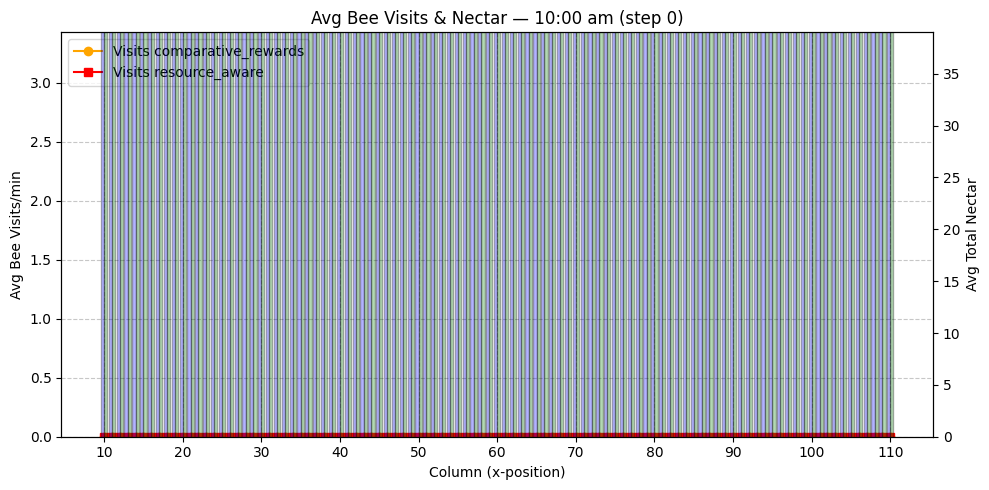

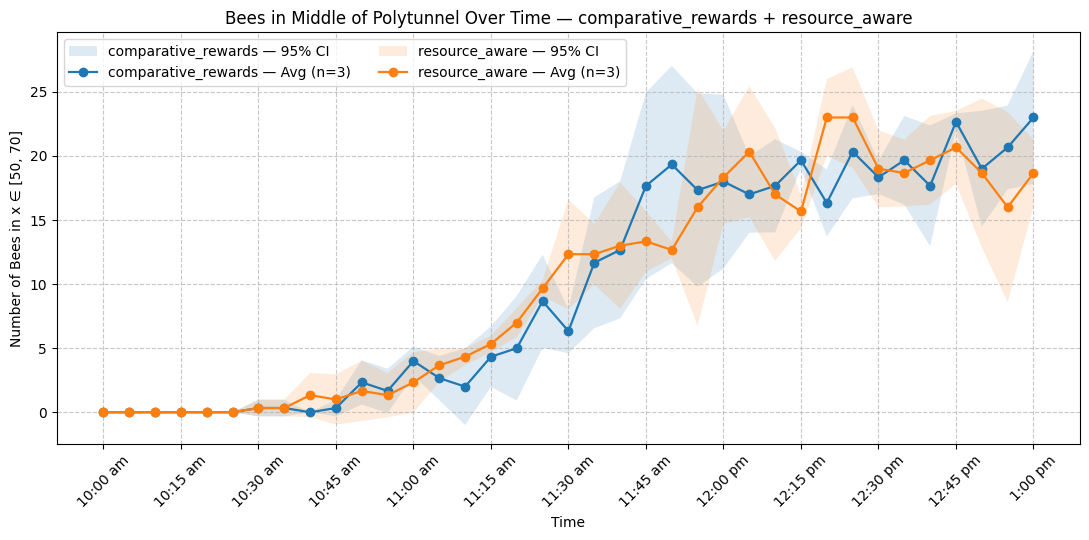

In [7]:
X_MIN, X_MAX = 50, 70
SAMPLE_EVERY = 300

# 1) Concatenate all behaviors into one DataFrame with a 'behavior' column
frames = []
for beh, df in dfs_by_behavior.items():
    tmp = df.copy()
    tmp["behavior"] = beh
    frames.append(tmp)
alldf = pd.concat(frames, ignore_index=True)

# 2) Keep Bee agents and prepare fields
bee_df = alldf[alldf["Agent Type"] == "bee"].copy()
bee_df["Step"] = bee_df["Step"].astype(int)

# Extract x coordinate if stored as Position=(x,y); if you already have an 'x' column, comment this out
bee_df["x"] = bee_df["Position"].apply(
    lambda pos: pos[0] if isinstance(pos, (list, tuple)) else None
)
bee_df = bee_df.dropna(subset=["x", "seed", "behavior"])

# Optional downsample to speed up / match other figures
if SAMPLE_EVERY and SAMPLE_EVERY > 1:
    bee_df = bee_df[bee_df["Step"] % SAMPLE_EVERY == 0]

# Flag bees inside the middle band
bee_df["in_middle"] = bee_df["x"].between(X_MIN, X_MAX, inclusive="both")

# 3) Count per Step per seed per behavior (run-level counts)
counts_per_run = (
    bee_df.groupby(["behavior", "Step", "seed"])["in_middle"]
    .sum()
    .reset_index(name="CountInMiddle")
)

# 4) Aggregate across runs (per behavior): mean and 95% CI at each Step
stats = (
    counts_per_run.groupby(["behavior", "Step"])["CountInMiddle"]
    .agg(["mean", "std", "count"])
    .reset_index()
    .rename(columns={"mean": "AvgCount", "std": "StdDev", "count": "NumRuns"})
)
stats["CI95"] = 1.96 * (stats["StdDev"] / np.sqrt(stats["NumRuns"]))

# Helper: map step -> clock time (starting 9:00)
def step_to_time_str(step):
    hh = 10 + step // 3600
    mm = (step % 3600) // 60
    suffix = "am" if hh < 12 else ("pm" if hh > 12 else "pm")
    hh12 = hh if 1 <= hh <= 12 else (hh - 12 if hh > 12 else 12)
    return f"{hh12}:{mm:02d} {suffix}"

# Build a global step axis (union of steps across behaviors)
all_steps = np.sort(stats["Step"].unique())
time_labels = [step_to_time_str(s) for s in all_steps]

# 5) Plot: one line + CI per behavior
plt.figure(figsize=(11, 5.5))

for beh in stats["behavior"].unique():
    sub = stats[stats["behavior"] == beh].sort_values("Step")

    # Shaded CI
    plt.fill_between(
        sub["Step"],
        sub["AvgCount"] - sub["CI95"],
        sub["AvgCount"] + sub["CI95"],
        alpha=0.15,
        label=f"{beh} — 95% CI"
    )
    # Mean line

    n_runs = int(sub["NumRuns"].median()) if len(sub) else 0
    plt.plot(
        sub["Step"],
        sub["AvgCount"],
        marker="o",
        linewidth=1.6,
        label=f"{beh} — Avg (n={n_runs})"
    )

tick_every = max(1, len(all_steps) // 10)
plt.xticks(all_steps[::tick_every], time_labels[::tick_every], rotation=45)

plt.xlabel("Time")
plt.ylabel(f"Number of Bees in x ∈ [{X_MIN}, {X_MAX}]")
beh_list_str = " + ".join(stats["behavior"].unique())
plt.title(f"Bees in Middle of Polytunnel Over Time — {beh_list_str}")
plt.grid(True, linestyle="--", alpha=0.7)
plt.legend(ncol=2, frameon=True)
plt.tight_layout()
plt.show()


# Plot: Depetion rate of nectar


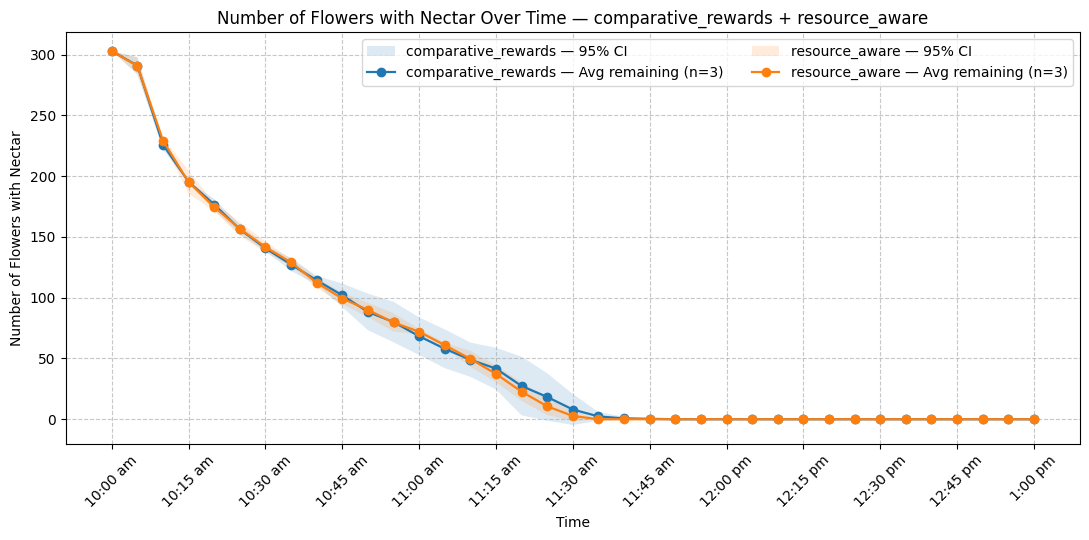

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



# ---------------- CONFIG ----------------
SAMPLE_EVERY = 300 
DEPLETED_EPS = 1e-9      # nectar <= eps is considered exploited
# ---------------------------------------

# 1) Concatenate all behaviors into one DataFrame with a 'behavior' column
frames = []
for beh, df in dfs_by_behavior.items():
    tmp = df.copy()
    tmp["behavior"] = beh
    frames.append(tmp)
alldf = pd.concat(frames, ignore_index=True)

# 2) Keep Plant agents, prep fields
plant_df = alldf[alldf["Agent Type"] == "plant"].copy()
plant_df["Step"] = plant_df["Step"].astype(int)
plant_df = plant_df.dropna(subset=["Plant nectar amount", "seed", "behavior"])

# Optional downsample
if SAMPLE_EVERY and SAMPLE_EVERY > 1:
    plant_df = plant_df[plant_df["Step"] % SAMPLE_EVERY == 0]

# Remaining = flowers with nectar > eps
plant_df["is_remaining"] = plant_df["Plant nectar amount"] > DEPLETED_EPS

# 3) Count remaining per (behavior, Step, seed)
rem_counts_per_run = (
    plant_df.groupby(["behavior", "Step", "seed"])["is_remaining"]
    .sum()
    .reset_index(name="NumRemaining")
)

# 4) Aggregate across runs: mean & 95% CI per behavior-step
stats = (
    rem_counts_per_run.groupby(["behavior", "Step"])["NumRemaining"]
    .agg(["mean", "std", "count"])
    .reset_index()
    .rename(columns={"mean": "AvgRemaining", "std": "StdDev", "count": "NumRuns"})
)
stats["CI95"] = 1.96 * (stats["StdDev"] / np.sqrt(stats["NumRuns"]))

# Helper: step -> clock time (start at 9:00)
def step_to_time_str(step):
    hh = 10 + step // 3600
    mm = (step % 3600) // 60
    suffix = "am" if hh < 12 else ("pm" if hh > 12 else "pm")
    hh12 = hh if 1 <= hh <= 12 else (hh - 12 if hh > 12 else 12)
    return f"{hh12}:{mm:02d} {suffix}"

all_steps = np.sort(stats["Step"].unique())
time_labels = [step_to_time_str(s) for s in all_steps]

# 5) Plot: Remaining flowers over time (per behavior)
plt.figure(figsize=(11, 5.5))

for beh in stats["behavior"].unique():
    sub = stats[stats["behavior"] == beh].sort_values("Step")
    n_runs = int(sub["NumRuns"].median()) if len(sub) else 0

    # 95% CI band
    plt.fill_between(
        sub["Step"],
        sub["AvgRemaining"] - sub["CI95"],
        sub["AvgRemaining"] + sub["CI95"],
        alpha=0.15,
        label=f"{beh} — 95% CI"
    )
    # Mean line
    plt.plot(
        sub["Step"], sub["AvgRemaining"],
        marker="o", linewidth=1.6,
        label=f"{beh} — Avg remaining (n={n_runs})"
    )

tick_every = max(1, len(all_steps) // 10)
plt.xticks(all_steps[::tick_every], time_labels[::tick_every], rotation=45)

plt.xlabel("Time")
plt.ylabel("Number of Flowers with Nectar")
beh_list_str = " + ".join(stats["behavior"].unique())
plt.title(f"Number of Flowers with Nectar Over Time — {beh_list_str}")
plt.grid(True, linestyle="--", alpha=0.7)
plt.legend(ncol=2, frameon=True)
plt.tight_layout()
plt.show()


# Plot: The change in likelihood in making a long jump

X-axis: time of the simulation

Y-axis: the probability of a bee making a long jump

In [9]:
# import pandas as pd
# import numpy as np
# import matplotlib.pyplot as plt

# def plot_long_jump_likelihood_by_behavior(
#     data,
#     long_jump_threshold=None,   # required if "Long jump" is NOT present
#     smooth_window=60,
#     show_policy=True,
# ):
#     """
#     data: either
#       - dict[str, DataFrame] mapping behavior -> df  (we add 'behavior' and concat), or
#       - a single DataFrame that already has 'behavior'
#     Assumes the rows are agent-time snapshots collected by Mesa's DataCollector.

#     Required columns: 'Agent Type', 'Step', 'Position'
#     Recommended: 'seed' (for CI)
#     Optional: 'Long jump' (bool), 'Reward window mean' (float)
#     """

#     # ---- unify input ----
#     if isinstance(data, dict):
#         frames = []
#         for beh, df in data.items():
#             tmp = df.copy()
#             tmp["behavior"] = beh
#             frames.append(tmp)
#         alldf = pd.concat(frames, ignore_index=True)
#     else:
#         alldf = data.copy()
#         if "behavior" not in alldf.columns:
#             raise ValueError("When passing a single DataFrame, it must include a 'behavior' column.")

#     # bees only
#     bee = alldf[alldf["Agent Type"] == "bee"].copy().reset_index(drop=True)
#     if "Step" not in bee.columns:
#         raise ValueError("Missing 'Step' column.")
#     bee["Step"] = bee["Step"].astype(int)

#     # ensure 'seed' exists for CI; if not, create a dummy
#     if "seed" not in bee.columns:
#         bee["seed"] = 0

#     # ---- realized rate ----
#     if "Long jump" in bee.columns:
#         bee["is_long"] = bee["Long jump"].astype(bool)
#     else:
#         if long_jump_threshold is None:
#             raise ValueError("No 'Long jump' column; provide long_jump_threshold to derive from positions.")
#         # sort for proper deltas within behavior/seed/bee
#         bee = bee.sort_values(["behavior", "seed", "unique_id", "Step"]).copy()
#         prev_pos = bee.groupby(["behavior", "seed", "unique_id"])["Position"].shift(1)

#         def _dist(p, q):
#             if (p is None) or (q is None):
#                 return np.nan
#             x1, y1 = p; x2, y2 = q
#             return ((x2 - x1)**2 + (y2 - y1)**2) ** 0.5

#         bee["step_len"] = [_dist(p, q) for p, q in zip(bee["Position"], prev_pos)]
#         bee["is_long"] = bee["step_len"] > float(long_jump_threshold)

#     realized_per_run = (
#         bee.dropna(subset=["is_long"])
#            .groupby(["behavior", "seed", "Step"])["is_long"]
#            .mean()
#            .reset_index(name="RealizedRate")
#     )

#     realized_stats = (
#         realized_per_run.groupby(["behavior", "Step"])["RealizedRate"]
#         .agg(['mean', 'std', 'count'])
#         .reset_index()
#         .rename(columns={'mean':'RealizedMean','std':'RealizedStd','count':'NumRuns'})
#     )
#     realized_stats["RealizedCI95"] = 1.96 * (realized_stats["RealizedStd"] / realized_stats["NumRuns"].clip(lower=1).pow(0.5))
#     realized_stats = realized_stats.sort_values(["behavior", "Step"])
#     realized_stats["RealizedSmooth"] = (
#         realized_stats.groupby("behavior")["RealizedMean"]
#         .transform(lambda s: s.rolling(smooth_window, min_periods=1).mean())
#     )
#     realized_stats["RealizedLow"]  = (realized_stats["RealizedMean"] - realized_stats["RealizedCI95"]).clip(lower=0)
#     realized_stats["RealizedHigh"] = (realized_stats["RealizedMean"] + realized_stats["RealizedCI95"]).clip(upper=1)

#     # ---- policy-implied propensity (optional) ----
#     policy_stats = None
#     if show_policy and ("Reward window mean" in bee.columns):
#         pol = bee[~bee["Reward window mean"].isna()].copy()
#         if len(pol):
#             pol["Propensity"] = 1.0 - pol["Reward window mean"].astype(float)
#             policy_per_run = (
#                 pol.groupby(["behavior", "seed", "Step"])["Propensity"]
#                    .mean().reset_index(name="PolicyProp")
#             )
#             policy_stats = (
#                 policy_per_run.groupby(["behavior","Step"])["PolicyProp"]
#                 .agg(['mean','std','count']).reset_index()
#                 .rename(columns={'mean':'PolicyMean','std':'PolicyStd','count':'NumRuns'})
#             )
#             policy_stats["PolicyCI95"] = 1.96 * (policy_stats["PolicyStd"] / policy_stats["NumRuns"].clip(lower=1).pow(0.5))
#             policy_stats = policy_stats.sort_values(["behavior","Step"])
#             policy_stats["PolicySmooth"] = (
#                 policy_stats.groupby("behavior")["PolicyMean"]
#                 .transform(lambda s: s.rolling(smooth_window, min_periods=1).mean())
#             )

#     # ---- plot ----
#     plt.figure(figsize=(11,6))
#     for beh in realized_stats["behavior"].unique():
#         sub_r = realized_stats[realized_stats["behavior"] == beh]
#         n_runs = int(sub_r["NumRuns"].median()) if len(sub_r) else 0

#         # shaded CI + smoothed realized line
#         plt.fill_between(sub_r["Step"], sub_r["RealizedLow"], sub_r["RealizedHigh"],
#                          alpha=0.12, label=f"{beh} — Realized 95% CI")
#         plt.plot(sub_r["Step"], sub_r["RealizedSmooth"], linewidth=1.8,
#                  label=f"{beh} — Realized (n={n_runs})")

#         # policy line (if available)
#         if policy_stats is not None:
#             sub_p = policy_stats[policy_stats["behavior"] == beh]
#             if len(sub_p):
#                 plt.plot(sub_p["Step"], sub_p["PolicySmooth"], linestyle="--", alpha=0.9,
#                          label=f"{beh} — Policy (1 - reward mean)")

#     plt.ylim(0, 1)
#     plt.xlabel("Step (s)")
#     plt.ylabel("Probability / Fraction")
#     plt.title("Likelihood of Long Jumps Over Time — by Behavior")
#     plt.grid(True, linestyle="--", alpha=0.5)
#     plt.legend(ncol=2, frameon=True)
#     plt.tight_layout()
#     plt.show()


In [10]:
# plot_long_jump_likelihood_by_behavior(dfs_by_behavior, smooth_window=60)